# Biological Plausibility: scArches

- **Purpose:** Repeat the matching and plausibility chain for the scArches winner (config 47).
- **Inputs:** Shared artifact; scArches query model and 10,000-HVG list; joint MLM scores.
- **Outputs:** `figures/BIOVAL/scarches_quick/`; caches under `models/validation/bio_scarches_cfg47/`.
- **Result:** The scArches candidates largely agree with the joint result; the joint representation remains primary.


In [1]:
from pathlib import Path
import sys

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import scvi
import gseapy as gp
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score

SEED = 0

def set_seed(seed):
    scvi.settings.seed = seed
    np.random.seed(seed)

set_seed(SEED)

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils import load_config

cfg = load_config()

APPROACH = "scarches"
CONFIG_ID = 47
NUM_HVG = 10000
K_MATCHING = 100
TUMOR_RES = 0.9
LEIDEN_SEED = 0
GRAPH_SEED = 0
MARGIN_CANDIDATE = 0.10
FORCE_RECOMPUTE = False

INPUT = Path.cwd() / "adata_config10_joint" / "config10_joint_3k.h5ad"
HVG_FILE = ROOT / cfg["paths"]["hpo"]["runs"] / f"hvg{NUM_HVG}" / "hvg_genes.txt"
RUN_DIR = ROOT / cfg["paths"]["hpo"]["runs"] / f"hvg{NUM_HVG}" / f"config_{CONFIG_ID:02d}" / APPROACH
MODEL_DIR = RUN_DIR / "query"
DE_DIR = ROOT / cfg["paths"]["models"] / "validation" / f"bio_{APPROACH}_cfg{CONFIG_ID:02d}" / "de_signatures"
GSEA_DIR = DE_DIR / "gsea_hallmark"
LINE_VS_TUMOR_DIR = DE_DIR / "line_vs_tumor"
MLM_ARTIFACT = ROOT / cfg["paths"]["models"] / "validation" / "bio_joint_cfg10" / "de_signatures" / "hallmark_mlm" / "hallmark_mlm_scores.h5ad"
HALLMARK_GMT = ROOT / "data" / "Gene_sets" / "h_cleaned.all.v2023.1.Hs.symbols.gmt"
FIG_DIR = ROOT / "figures" / "BIOVAL" / "scarches_quick"
MATCHING_ARTIFACT = DE_DIR / "scarches_latent_groups.h5ad"

for directory in [DE_DIR, GSEA_DIR, LINE_VS_TUMOR_DIR, FIG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print(f"Approach {APPROACH}, config {CONFIG_ID}, {NUM_HVG} HVGs")
print(f"Model dir: {MODEL_DIR}")
print(f"DE dir:    {DE_DIR}")


def tumor_group_sort_key(group):
    return int(str(group).rsplit("_", 1)[-1])


def read_gmt(path):
    sets = {}
    for line in open(path):
        parts = line.rstrip("\n").split("\t")
        sets[parts[0]] = [g for g in parts[2:] if g]
    return sets


hallmark_sets = read_gmt(HALLMARK_GMT)


def make_lfc_ranking(de):
    return (
        de[["gene", "lfc_mean"]]
        .dropna()
        .drop_duplicates("gene")
        .sort_values(["lfc_mean", "gene"], ascending=[False, True])
        .reset_index(drop=True)
    )


def run_hallmark_prerank(ranking, comparison):
    res = gp.prerank(
        rnk=ranking,
        gene_sets=str(HALLMARK_GMT),
        seed=SEED,
        method="permutation",
        permutation_num=1000,
        min_size=15,
        max_size=500,
        weight=1,
        ascending=False,
        outdir=None,
    ).res2d.copy()
    res = res.rename(columns={
        "Term": "pathway", "ES": "es", "NES": "nes",
        "NOM p-val": "nom_pval", "FDR q-val": "fdr_qval",
        "FWER p-val": "fwer_pval", "Tag %": "tag_pct",
        "Gene %": "gene_pct", "Lead_genes": "lead_genes",
    })
    res["pathway"] = res["pathway"].str.replace("^HALLMARK_", "", regex=True)
    res["set_size"] = res["pathway"].map(lambda p: len(hallmark_sets.get(p, [])))
    res["overlap"] = res["pathway"].map(lambda p: len(set(ranking["gene"]) & set(hallmark_sets.get(p, []))))
    return res.assign(comparison=comparison)


MODEL_INPUTS = {}


def get_model_inputs():
    """Load the full artifact and the scArches query model on first use."""
    if not MODEL_INPUTS:
        print("Loading the full artifact and the scArches query model ...")
        full = ad.read_h5ad(INPUT)
        hvg_genes = [g for g in HVG_FILE.read_text().splitlines() if g]
        missing = [g for g in hvg_genes if g not in full.var_names]
        assert not missing, (len(missing), missing[:5])
        combined_hvg = full[:, hvg_genes].copy()
        model = scvi.model.SCANVI.load(str(MODEL_DIR), adata=combined_hvg)
        MODEL_INPUTS.update(combined_hvg=combined_hvg, model=model)
    return MODEL_INPUTS["combined_hvg"], MODEL_INPUTS["model"]

Seed set to 0


Approach scarches, config 47, 10000 HVGs
Model dir: /mnt/bigdisk/markus/CRC-scMFmap/models/hpo/runs/hvg10000/config_47/scarches/query
DE dir:    /mnt/bigdisk/markus/CRC-scMFmap/models/validation/bio_scarches_cfg47/de_signatures


In [2]:
MATCHING_SETTINGS = {
    "model_dir": str(MODEL_DIR),
    "num_hvg": int(NUM_HVG),
    "tumor_res": float(TUMOR_RES),
    "leiden_seed": int(LEIDEN_SEED),
    "graph_seed": int(GRAPH_SEED),
}
MATCHING_OBS_COLUMNS = [
    "dataset", "cell_line", "label",
    "tumor_leiden_res0.9", "match_group_scarches",
]
MATCHING_OBMS = ["X_latent", "X_latent_scarches", "X_umap_scarches"]


def build_matching_artifact():
    combined_full = ad.read_h5ad(INPUT)
    print(f"Artifact: {INPUT}")
    print(f"Shape: {combined_full.shape} | counts layer: {'counts' in combined_full.layers}")

    hvg_genes = [g for g in HVG_FILE.read_text().splitlines() if g]
    assert len(hvg_genes) == NUM_HVG, len(hvg_genes)
    missing = [g for g in hvg_genes if g not in combined_full.var_names]
    assert not missing, (len(missing), missing[:5])

    combined_hvg = combined_full[:, hvg_genes].copy()
    assert combined_hvg.var_names.equals(pd.Index(hvg_genes))
    print(f"Model input: {combined_hvg.shape}")

    model = scvi.model.SCANVI.load(str(MODEL_DIR), adata=combined_hvg)
    assert combined_hvg.var_names.equals(model.adata.var_names)
    latent = np.asarray(model.get_latent_representation(combined_hvg))
    combined_full.obsm["X_latent_scarches"] = latent
    combined_hvg.obsm["X_latent_scarches"] = latent
    MODEL_INPUTS.update(combined_hvg=combined_hvg, model=model)
    print(f"Latent: {latent.shape}")

    sc.pp.neighbors(combined_full, use_rep="X_latent_scarches", random_state=GRAPH_SEED)
    sc.tl.umap(combined_full, random_state=GRAPH_SEED)
    combined_full.obsm["X_umap_scarches"] = combined_full.obsm["X_umap"].copy()

    dataset = combined_full.obs["dataset"].astype(str).to_numpy()
    is_tumor = dataset == "tumor"
    is_line = ~is_tumor

    tumor_adata = combined_full[is_tumor].copy()
    sc.pp.neighbors(tumor_adata, use_rep="X_latent_scarches", random_state=GRAPH_SEED)
    sc.tl.leiden(
        tumor_adata,
        resolution=TUMOR_RES,
        key_added="tumor_leiden_scarches",
        random_state=LEIDEN_SEED,
        flavor="igraph",
        n_iterations=2,
    )

    match_group = pd.Series(pd.NA, index=combined_full.obs.index, dtype="string", name="match_group_scarches")
    match_group.loc[tumor_adata.obs_names] = (
        "tumor_" + tumor_adata.obs["tumor_leiden_scarches"].astype(str)
    ).to_numpy()
    match_group.loc[combined_full.obs_names[is_line]] = (
        "line_" + combined_full.obs.loc[is_line, "cell_line"].astype(str)
    ).to_numpy()
    assert match_group.notna().all()
    combined_full.obs["match_group_scarches"] = match_group

    artifact = ad.AnnData(
        X=np.zeros((combined_full.n_obs, 0), dtype=np.float32),
        obs=combined_full.obs[MATCHING_OBS_COLUMNS].copy(),
    )
    for key in MATCHING_OBMS:
        artifact.obsm[key] = np.asarray(combined_full.obsm[key])
    artifact.uns["scarches_matching_settings"] = MATCHING_SETTINGS
    artifact.write_h5ad(MATCHING_ARTIFACT, compression="gzip")
    print(f"Saved matching artifact: {MATCHING_ARTIFACT}")
    return combined_full


def cached_matching_artifact():
    if FORCE_RECOMPUTE or not MATCHING_ARTIFACT.exists():
        return None
    cached = ad.read_h5ad(MATCHING_ARTIFACT)
    cached_settings = {key: str(value) for key, value in dict(cached.uns.get("scarches_matching_settings", {})).items()}
    expected_settings = {key: str(value) for key, value in MATCHING_SETTINGS.items()}
    missing_obs = [column for column in MATCHING_OBS_COLUMNS if column not in cached.obs.columns]
    missing_obsm = [key for key in MATCHING_OBMS if key not in cached.obsm]
    if cached_settings != expected_settings or missing_obs or missing_obsm:
        print("Cached matching artifact is stale or incomplete; rebuilding.")
        print(f"  settings match: {cached_settings == expected_settings}")
        print(f"  missing obs: {missing_obs} | missing obsm: {missing_obsm}")
        return None
    print(f"Loaded cached matching artifact: {MATCHING_ARTIFACT}")
    return cached


combined_full = cached_matching_artifact()
if combined_full is None:
    combined_full = build_matching_artifact()

dataset = combined_full.obs["dataset"].astype(str).to_numpy()
cell_lines = combined_full.obs["cell_line"].astype(str).to_numpy()
is_tumor = dataset == "tumor"
is_line = ~is_tumor

tumor_labels = (
    combined_full.obs.loc[is_tumor, "match_group_scarches"]
    .astype(str).str.replace("tumor_", "", regex=False)
)
cluster_order = sorted(tumor_labels.unique(), key=int)
sizes = tumor_labels.value_counts().reindex(cluster_order)
share = sizes / sizes.sum()
joint_labels = combined_full.obs.loc[is_tumor, "tumor_leiden_res0.9"].astype(str)
pelka_labels = combined_full.obs.loc[is_tumor, "label"].astype(str)

print(f"Clusters: {len(cluster_order)} | min {sizes.min()} | max {sizes.max()}")
print(f"Max share: {share.max():.3f} | fragments (<50): {int((sizes < 50).sum())}")
print(f"ARI vs joint partition: {adjusted_rand_score(joint_labels, tumor_labels):.3f}")
print(f"AMI vs Pelka labels:    {adjusted_mutual_info_score(pelka_labels, tumor_labels):.3f}")
display(pd.DataFrame({"cells": sizes, "share": share.round(3)}))

group_values = combined_full.obs["match_group_scarches"].astype(str).to_numpy()
TUMOR_ORDER = sorted(pd.unique(group_values[is_tumor]), key=tumor_group_sort_key)
print(f"Tumor groups: {len(TUMOR_ORDER)}")

Loaded cached matching artifact: /mnt/bigdisk/markus/CRC-scMFmap/models/validation/bio_scarches_cfg47/de_signatures/scarches_latent_groups.h5ad
Clusters: 19 | min 230 | max 15032
Max share: 0.139 | fragments (<50): 0
ARI vs joint partition: 0.463
AMI vs Pelka labels:    0.426


,cells,share
match_group_scarches,,
0,9417,0.087
1,9771,0.090
2,15032,0.139
3,8423,0.078
4,230,0.002
5,4390,0.041
6,8965,0.083
7,7006,0.065
8,1746,0.016


Tumor groups: 19


## Candidate Matches

In [3]:
def knn_matches(latent, groups, is_tumor, is_line, cell_lines, k):
    latent = np.asarray(latent)
    groups = np.asarray(groups, dtype=str)
    is_tumor = np.asarray(is_tumor)
    is_line = np.asarray(is_line)
    cell_lines = np.asarray(cell_lines, dtype=str)

    nn = NearestNeighbors(n_neighbors=k, metric="euclidean").fit(latent[is_tumor])
    dist, idx = nn.kneighbors(latent[is_line])
    neighbor_groups = groups[is_tumor][idx]

    group_order = sorted(pd.unique(groups[is_tumor]), key=tumor_group_sort_key)
    composition = pd.DataFrame(
        {g: (neighbor_groups == g).mean(axis=1) for g in group_order},
        index=np.where(is_line)[0],
    )
    composition.insert(0, "cell_line", cell_lines[is_line])
    composition["nearest_tumor_distance"] = dist[:, 0]
    for g in group_order:
        member = neighbor_groups == g
        composition[f"dist_{g}"] = np.where(
            member.any(axis=1),
            np.where(member, dist, np.inf).min(axis=1),
            np.nan,
        )

    baseline_nn = NearestNeighbors(n_neighbors=2, metric="euclidean").fit(latent[is_tumor])
    baseline = float(np.quantile(baseline_nn.kneighbors(latent[is_tumor])[0][:, 1], 0.95))

    rows = []
    for cell_line in sorted(pd.unique(cell_lines[is_line])):
        cells = composition.loc[composition["cell_line"].eq(cell_line)]
        mean_comp = cells[group_order].mean().sort_values(ascending=False)
        primary, second = mean_comp.index[0], mean_comp.index[1]
        rows.append({
            "cell_line": cell_line,
            "n_cells": int(cells.shape[0]),
            "primary_match": primary,
            "primary_frac": float(mean_comp.iloc[0]),
            "second_match": second,
            "second_frac": float(mean_comp.iloc[1]),
            "margin": float(mean_comp.iloc[0] - mean_comp.iloc[1]),
            "median_dist_nearest_tumor": float(cells["nearest_tumor_distance"].median()),
            "median_dist_primary": float(cells[f"dist_{primary}"].median()),
            "median_dist_second": float(cells[f"dist_{second}"].median()),
            "frac_cells_matched_neighbor": float(cells[f"dist_{primary}"].notna().mean()),
            "low_proximity": bool(cells["nearest_tumor_distance"].median() > baseline),
        })
    matches = pd.DataFrame(rows).set_index("cell_line")
    return composition, matches, baseline, group_order


cell_knn, line_matches, proximity_baseline, _ = knn_matches(
    combined_full.obsm["X_latent_scarches"],
    combined_full.obs["match_group_scarches"],
    is_tumor, is_line, cell_lines, k=K_MATCHING,
)
line_composition = cell_knn.groupby("cell_line", observed=True)[TUMOR_ORDER].mean()
line_matches["multiple_viable"] = line_matches["margin"] < MARGIN_CANDIDATE

joint_group_values = np.where(
    is_tumor,
    "tumor_" + combined_full.obs["tumor_leiden_res0.9"].astype(str).to_numpy(),
    "line_" + combined_full.obs["cell_line"].astype(str).to_numpy(),
)
joint_composition, joint_matches, joint_baseline, _ = knn_matches(
    combined_full.obsm["X_latent"],
    joint_group_values,
    is_tumor, is_line, cell_lines, k=K_MATCHING,
)

LINE_ORDER = sorted(
    line_matches.index,
    key=lambda cl: (
        tumor_group_sort_key(line_matches.loc[cl, "primary_match"]),
        -float(line_matches.loc[cl, "margin"]),
    ),
)

print(f"scArches tumor-tumor q95 baseline: {proximity_baseline:.3f}")
print(f"Joint    tumor-tumor q95 baseline: {joint_baseline:.3f}")
display(line_matches.loc[LINE_ORDER].round(3))

comparison = pd.DataFrame({
    "joint_primary": joint_matches["primary_match"],
    "joint_margin": joint_matches["margin"],
    "joint_nearest": joint_matches["median_dist_nearest_tumor"],
    "scarches_primary": line_matches["primary_match"],
    "scarches_margin": line_matches["margin"],
    "scarches_nearest": line_matches["median_dist_nearest_tumor"],
})
comparison["same_primary"] = comparison["joint_primary"].eq(comparison["scarches_primary"])
display(comparison.round(3))
print(f"Same primary match for {int(comparison['same_primary'].sum())} of 10 cell lines")

line_matches.to_csv(DE_DIR / "scarches_line_matches_k100.csv")
joint_matches.to_csv(DE_DIR / "joint_line_matches_k100.csv")

scArches tumor-tumor q95 baseline: 1.370
Joint    tumor-tumor q95 baseline: 1.631


,n_cells,primary_match,primary_frac,second_match,second_frac,margin,median_dist_nearest_tumor,median_dist_primary,median_dist_second,frac_cells_matched_neighbor,low_proximity,multiple_viable
cell_line,,,,,,,,,,,,
HT55,211,tumor_2,0.815,tumor_6,0.092,0.722,1.208,1.234,1.592,0.991,False,False
LS180,362,tumor_2,0.790,tumor_6,0.080,0.710,1.118,1.152,1.552,0.989,False,False
NCIH747,80,tumor_2,0.807,tumor_3,0.100,0.707,1.346,1.378,1.789,0.962,False,False
RCM1,131,tumor_2,0.741,tumor_6,0.080,0.660,1.523,1.576,1.940,0.992,True,False
OUMS23,107,tumor_2,0.706,tumor_6,0.117,0.589,1.702,1.791,2.105,1.000,True,False
SNUC4,471,tumor_2,0.741,tumor_6,0.179,0.562,0.934,0.972,1.220,0.994,False,False
HCC56,102,tumor_2,0.628,tumor_1,0.098,0.531,1.091,1.142,1.292,0.951,False,False
CL34,418,tumor_2,0.731,tumor_6,0.204,0.527,0.970,1.006,1.214,0.986,False,False
CCK81,127,tumor_2,0.638,tumor_6,0.333,0.305,0.876,0.952,1.027,0.976,False,False


,joint_primary,joint_margin,joint_nearest,scarches_primary,scarches_margin,scarches_nearest,same_primary
cell_line,,,,,,,
CCK81,tumor_5,0.256,1.002,tumor_2,0.305,0.876,False
CL34,tumor_4,0.022,1.047,tumor_2,0.527,0.970,False
HCC56,tumor_4,0.268,1.335,tumor_2,0.531,1.091,False
HT55,tumor_4,0.196,1.371,tumor_2,0.722,1.208,False
LS1034,tumor_4,0.084,1.124,tumor_2,0.049,1.153,False
LS180,tumor_4,0.141,1.112,tumor_2,0.710,1.118,False
NCIH747,tumor_5,0.123,1.140,tumor_2,0.707,1.346,False
OUMS23,tumor_6,0.192,2.269,tumor_2,0.589,1.702,False
RCM1,tumor_5,0.289,1.219,tumor_2,0.660,1.523,False


Same primary match for 0 of 10 cell lines


# Matching Candidates and UMAPs

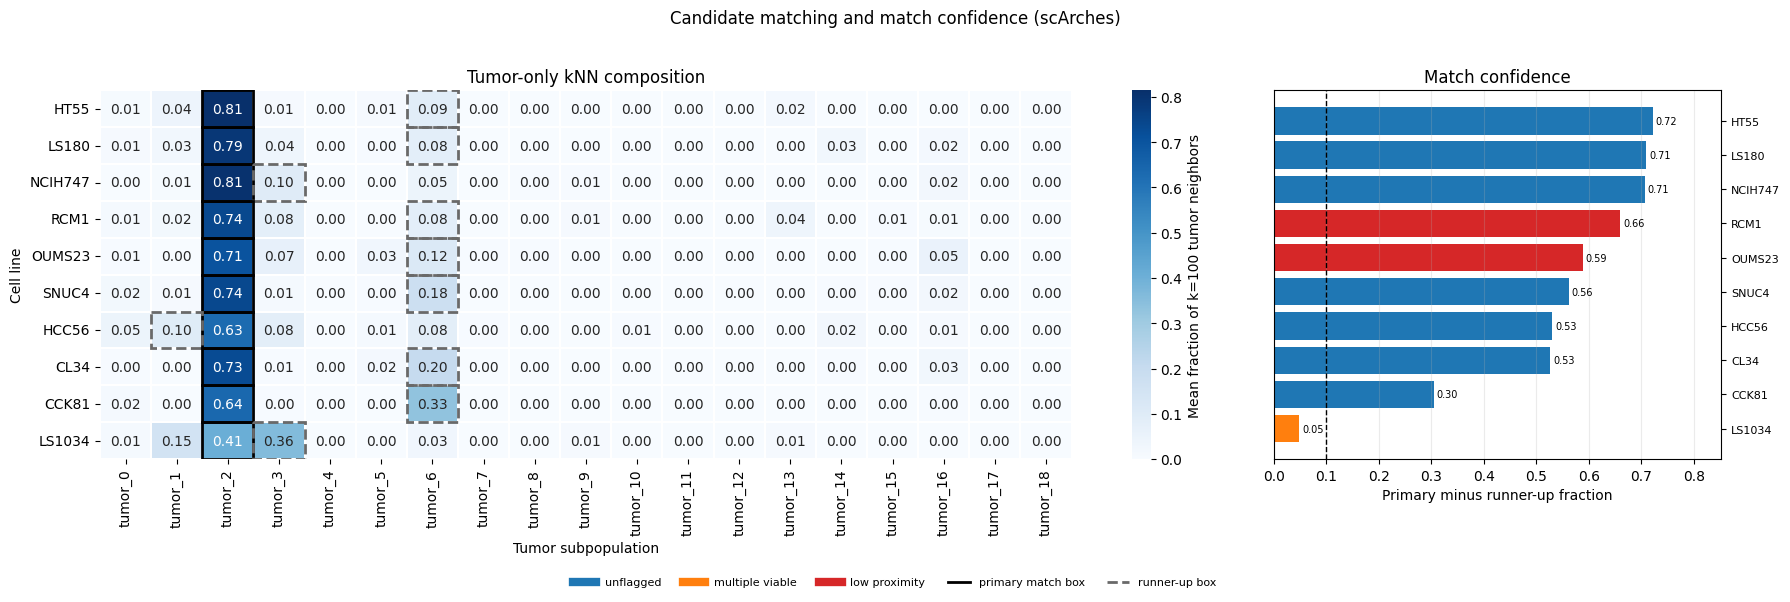

In [4]:
match_order = LINE_ORDER
composition_plot = line_composition.loc[match_order, TUMOR_ORDER]

fig, (ax_heat, ax_margin) = plt.subplots(
    ncols=2,
    figsize=(18, max(5, 0.55 * len(match_order))),
    gridspec_kw={"width_ratios": [3.8, 1.4]},
)

sns.heatmap(
    composition_plot,
    ax=ax_heat,
    cmap="Blues",
    vmin=0,
    vmax=max(0.25, float(composition_plot.to_numpy().max())),
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    cbar_kws={"label": f"Mean fraction of k={K_MATCHING} tumor neighbors"},
)
ax_heat.set_xlabel("Tumor subpopulation")
ax_heat.set_ylabel("Cell line")
ax_heat.set_title("Tumor-only kNN composition")
ax_heat.set_xticklabels(ax_heat.get_xticklabels(), rotation=90)

for y, cell_line in enumerate(match_order):
    primary = line_matches.loc[cell_line, "primary_match"]
    second = line_matches.loc[cell_line, "second_match"]
    for group, color, linestyle in [
        (primary, "black", "-"),
        (second, "dimgray", "--"),
    ]:
        if group in TUMOR_ORDER:
            x = TUMOR_ORDER.index(group)
            ax_heat.add_patch(Rectangle(
                (x, y), 1, 1, fill=False, edgecolor=color,
                linewidth=2.0, linestyle=linestyle,
            ))

margin_values = line_matches.loc[match_order, "margin"]
colors = [
    "tab:red" if bool(line_matches.loc[name, "low_proximity"])
    else "tab:orange" if bool(line_matches.loc[name, "multiple_viable"])
    else "tab:blue"
    for name in match_order
]
ax_margin.barh(np.arange(len(match_order)), margin_values, color=colors)
ax_margin.invert_yaxis()
ax_margin.axvline(MARGIN_CANDIDATE, color="black", linestyle="--", linewidth=1)
ax_margin.set_yticks(np.arange(len(match_order)))
ax_margin.set_yticklabels(match_order, fontsize=8)
ax_margin.yaxis.tick_right()
ax_margin.set_xlim(0, max(margin_values) * 1.18)
for y, value in enumerate(margin_values):
    ax_margin.text(value + 0.005, y, f"{value:.2f}", va="center", fontsize=7)
ax_margin.set_xlabel("Primary minus runner-up fraction")
ax_margin.set_title("Match confidence")
ax_margin.grid(axis="x", alpha=0.25)
fig.legend(
    handles=[
        Line2D([0], [0], color="tab:blue", lw=6, label="unflagged"),
        Line2D([0], [0], color="tab:orange", lw=6, label="multiple viable"),
        Line2D([0], [0], color="tab:red", lw=6, label="low proximity"),
        Line2D([0], [0], color="black", lw=2, label="primary match box"),
        Line2D([0], [0], color="dimgray", lw=2, linestyle="--", label="runner-up box"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.05),
    ncol=5,
    frameon=False,
    fontsize=8,
)

fig.suptitle("Candidate matching and match confidence (scArches)", y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / "scarches_matching_confidence.png", dpi=300, bbox_inches="tight")
plt.show()

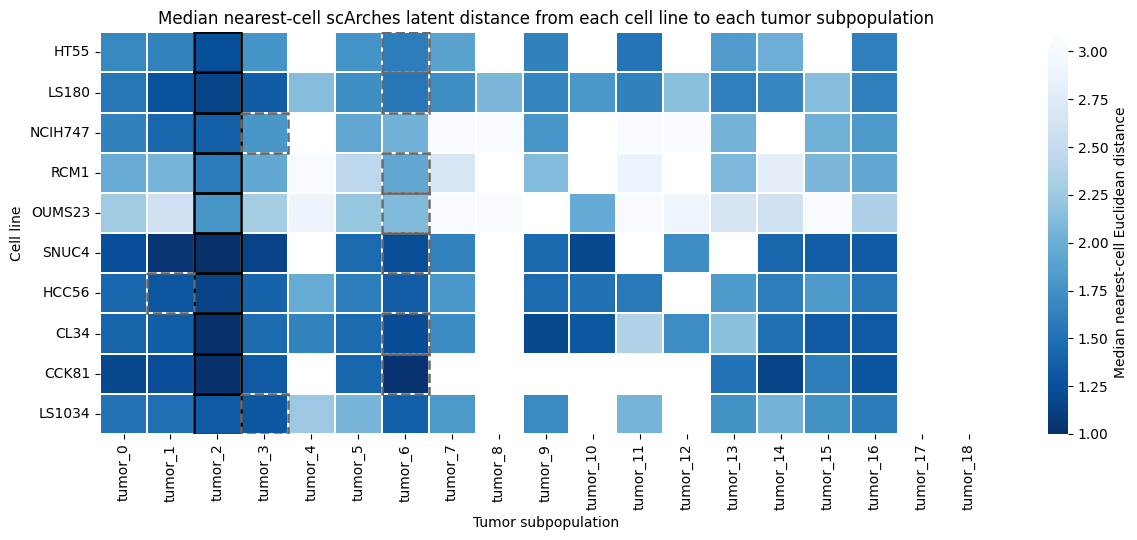

In [5]:
distance_columns = [f"dist_{group}" for group in TUMOR_ORDER]
line_distance_matrix = cell_knn.groupby("cell_line", observed=True)[distance_columns].median().loc[LINE_ORDER]
line_distance_matrix.columns = TUMOR_ORDER

fig_width = max(12, 0.65 * len(TUMOR_ORDER))
fig_height = max(5, 0.55 * len(line_distance_matrix))
fig, ax = plt.subplots(figsize=(fig_width, fig_height))
sns.heatmap(
    line_distance_matrix,
    ax=ax,
    cmap="Blues_r",
    vmin=1.0,
    vmax=3.0,
    linewidths=0.3,
    cbar_kws={"label": "Median nearest-cell Euclidean distance", "extend": "max"},
)
for y, cell_line in enumerate(line_distance_matrix.index):
    for group, color, linestyle in [
        (str(line_matches.loc[cell_line, "primary_match"]), "black", "-"),
        (str(line_matches.loc[cell_line, "second_match"]), "dimgray", "--"),
    ]:
        if group in TUMOR_ORDER:
            x = TUMOR_ORDER.index(group)
            ax.add_patch(Rectangle(
                (x, y), 1, 1, fill=False, edgecolor=color,
                linewidth=1.8, linestyle=linestyle,
            ))
ax.set_xlabel("Tumor subpopulation")
ax.set_ylabel("Cell line")
ax.set_title("Median nearest-cell scArches latent distance from each cell line to each tumor subpopulation")
plt.tight_layout()
fig.savefig(FIG_DIR / "scarches_line_subpop_distances.png", dpi=300, bbox_inches="tight")
plt.show()

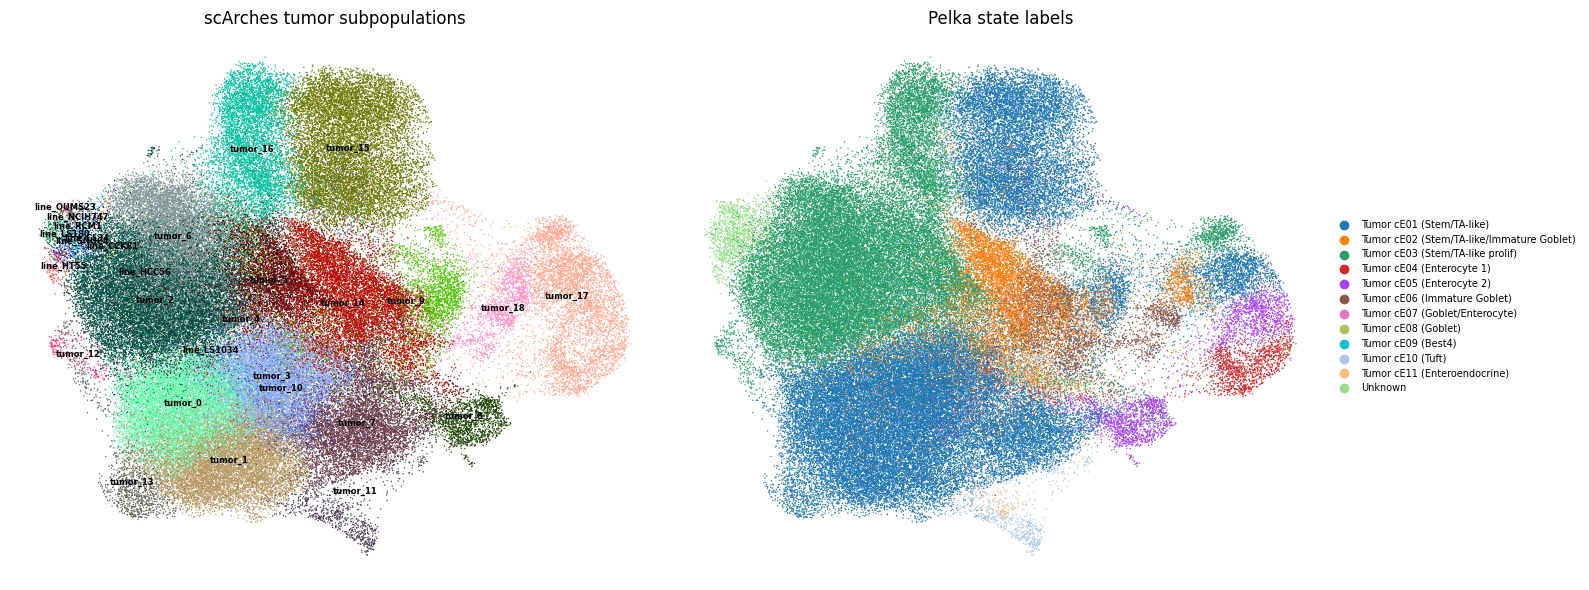

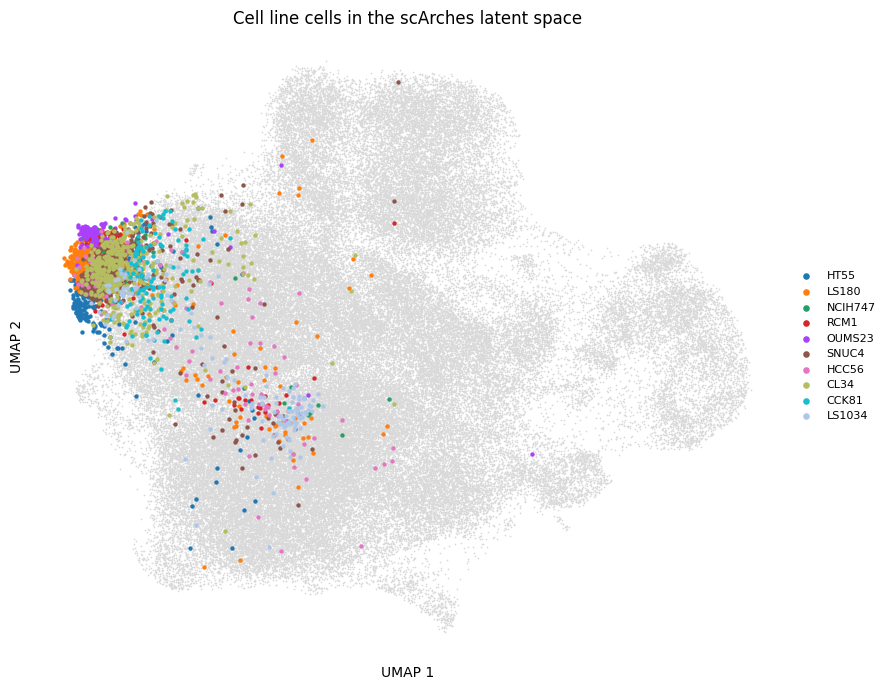

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sc.pl.embedding(
    combined_full, basis="X_umap_scarches", color="match_group_scarches",
    ax=axes[0], show=False, legend_loc="on data", legend_fontsize=6,
    frameon=False, size=4, na_color="#d9d9d9", na_in_legend=False,
    title="scArches tumor subpopulations",
)
sc.pl.embedding(
    combined_full, basis="X_umap_scarches", color="label",
    ax=axes[1], show=False, legend_loc="right margin", legend_fontsize=7,
    frameon=False, size=4, na_color="#d9d9d9", na_in_legend=False,
    title="Pelka state labels",
)
plt.tight_layout()
fig.savefig(FIG_DIR / "scarches_subpop_umap.png", dpi=300, bbox_inches="tight")
plt.show()

umap = combined_full.obsm["X_umap_scarches"]
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(umap[is_tumor, 0], umap[is_tumor, 1], s=1.5, c="#d9d9d9", linewidths=0, rasterized=True)
palette = ["#1f77b4", "#ff7f0e", "#279e68", "#d62728", "#aa40fc",
           "#8c564b", "#e377c2", "#b5bd61", "#17becf", "#aec7e8"]
for color, cell_line in zip(palette, LINE_ORDER):
    mask = is_line & (cell_lines == cell_line)
    ax.scatter(umap[mask, 0], umap[mask, 1], s=10, c=[color], linewidths=0, label=cell_line)
ax.set_title("Cell line cells in the scArches latent space")
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=8, markerscale=1.5)
plt.tight_layout()
fig.savefig(FIG_DIR / "scarches_line_umap.png", dpi=300, bbox_inches="tight")
plt.show()

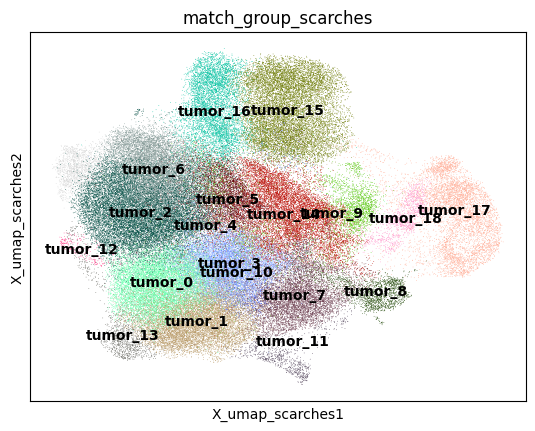

In [21]:
sc.pl.embedding(combined_full, mask_obs=combined_full.obs.dataset=="tumor", color="match_group_scarches",legend_loc="on data", basis="X_umap_scarches", na_in_legend=False)

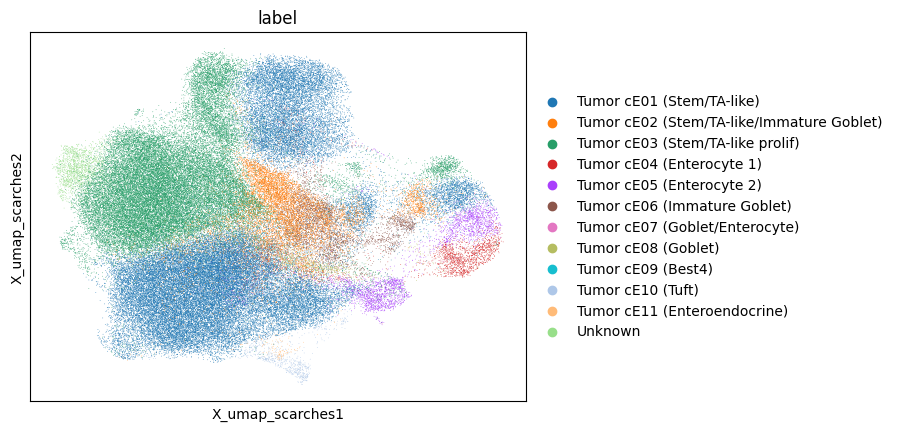

In [22]:
sc.pl.embedding(combined_full, color="label", basis="X_umap_scarches")

# Bio1: tumor-only scVI DEG,GSEA

In [7]:
DE_BATCH_CORRECTION = True
de_dir = DE_DIR / f"batch_correction_{str(DE_BATCH_CORRECTION).lower()}"
de_dir.mkdir(parents=True, exist_ok=True)

de_by_subpop = {}
rankings = {}

for subpopulation in TUMOR_ORDER:
    de_path = de_dir / f"scvi_de_{subpopulation}.csv"
    ranking_path = de_dir / f"ranking_{subpopulation}.csv"

    if de_path.exists() and not FORCE_RECOMPUTE:
        de = pd.read_csv(de_path)
    else:
        combined_hvg, model = get_model_inputs()
        print(f"running DE: {subpopulation}")
        idx1 = is_tumor & (group_values == subpopulation)
        idx2 = is_tumor & (group_values != subpopulation)
        de = model.differential_expression(
            adata=combined_hvg,
            batch_correction=DE_BATCH_CORRECTION,
            idx1=idx1,
            idx2=idx2,
            mode="change",
            delta=0.25,
            silent=True,
        )
        de.index.name = "gene"
        de = de.reset_index()
        de.insert(0, "subpopulation", subpopulation)
        de.insert(1, "n_source", int(idx1.sum()))
        de.insert(2, "n_rest", int(idx2.sum()))
        de.to_csv(de_path, index=False)

    if ranking_path.exists() and not FORCE_RECOMPUTE:
        ranking = pd.read_csv(ranking_path)
    else:
        ranking = make_lfc_ranking(de)
        ranking.to_csv(ranking_path, index=False)

    de_by_subpop[subpopulation] = de
    rankings[subpopulation] = ranking

de_qc = pd.DataFrame([
    {
        "subpopulation": subpopulation,
        "n_source": int(de["n_source"].iloc[0]),
        "n_rest": int(de["n_rest"].iloc[0]),
        "n_de_fdr_0.05": int(de["is_de_fdr_0.05"].sum()),
        "n_up_fdr_0.05": int((de["is_de_fdr_0.05"] & (de["lfc_mean"] > 0)).sum()),
        "n_down_fdr_0.05": int((de["is_de_fdr_0.05"] & (de["lfc_mean"] < 0)).sum()),
        "top_up_in_source": ", ".join(de.nlargest(10, "lfc_mean")["gene"]),
    }
    for subpopulation, de in de_by_subpop.items()
])
de_qc.to_csv(de_dir / "de_qc.csv", index=False)
display(de_qc)

,subpopulation,n_source,n_rest,n_de_fdr_0.05,n_up_fdr_0.05,n_down_fdr_0.05,top_up_in_source
0,tumor_0,9417,98714,0,0,0,"HMGB4, SLC1A3, SNCA, AC096649.2, GDF10, SULT2A..."
1,tumor_1,9771,98360,0,0,0,"HMGB4, SMOC2, BPIFA1, KRT5, PAX7, C1orf95, KCN..."
2,tumor_2,15032,93099,0,0,0,"TOP2A, HIST1H4C, UBE2C, CDKN2D, FAM72D, HJURP,..."
3,tumor_3,8423,99708,0,0,0,"KRT6A, EMP1, CAV1, IGFL1, GAST, AHNAK2, KRT16,..."
4,tumor_4,230,107901,11,11,0,"SST, DHRS9, PI3, MXRA5, PSORS1C2, KRT6A, SCEL,..."
5,tumor_5,4390,103741,0,0,0,"PIF1, HIST1H3B, ASPM, HIST1H2BM, POLQ, FAM72A,..."
6,tumor_6,8965,99166,0,0,0,"CCNB1, CDC20, PTTG1, CCNB2, CENPA, PLK1, CDKN3..."
7,tumor_7,7006,101125,0,0,0,"PYY, APOA4, TCHH, ANGPTL4, ANKRD36C, SEMA7A, R..."
8,tumor_8,1746,106385,2170,2151,19,"PYY, SEMA7A, APOA4, SST, POTEC, SGIP1, CHGA, R..."
9,tumor_9,3657,104474,0,0,0,"SST, CPB1, CALY, BPIFA1, CHGA, DEFA6, DEFA5, K..."


In [8]:
gsea_path = GSEA_DIR / "hallmark_prerank_tumor.csv"

if gsea_path.exists() and not FORCE_RECOMPUTE:
    results_gsea_tumor = pd.read_csv(gsea_path)
    print(f"Loaded cached tumor GSEA: {gsea_path}")
else:
    collected = []
    for subpopulation in TUMOR_ORDER:
        part_path = GSEA_DIR / f"gsea_tumor_{subpopulation}.csv"
        if part_path.exists() and not FORCE_RECOMPUTE:
            print(f"loading GSEA: {subpopulation}")
            res = pd.read_csv(part_path)
        else:
            print(f"running GSEA: {subpopulation}")
            res = run_hallmark_prerank(rankings[subpopulation], f"{subpopulation}-vs-rest")
            res.insert(0, "subpopulation", subpopulation)
            res.to_csv(part_path, index=False)
        collected.append(res)
    results_gsea_tumor = pd.concat(collected, ignore_index=True)
    results_gsea_tumor.to_csv(gsea_path, index=False)
    print(f"Saved tumor GSEA: {gsea_path}")

print(f"Rows: {results_gsea_tumor.shape}")
print(f"Pathways: {results_gsea_tumor['pathway'].nunique()}")
display(results_gsea_tumor.head(3))

ct = pd.crosstab(
    combined_full.obs.loc[is_tumor, "match_group_scarches"].astype(str),
    combined_full.obs.loc[is_tumor, "label"].astype(str),
)
dominant_label = ct.idxmax(axis=1)
prolif_arm = [g for g in TUMOR_ORDER if g in dominant_label.index and "cE03" in str(dominant_label.loc[g])]
print(f"cE03-dominated subpopulations: {prolif_arm}")

Loaded cached tumor GSEA: /mnt/bigdisk/markus/CRC-scMFmap/models/validation/bio_scarches_cfg47/de_signatures/gsea_hallmark/hallmark_prerank_tumor.csv
Rows: (931, 14)
Pathways: 49


,subpopulation,Name,pathway,es,nes,nom_pval,fdr_qval,fwer_pval,tag_pct,gene_pct,lead_genes,set_size,overlap,comparison
0,tumor_0,prerank,MYC_TARGETS_V2,0.782195,3.759577,0.0,0.0,0.0,25/32,9.55%,MYC;NPM1;MCM5;EXOSC5;UNG;HSPD1;CDK4;DUSP2;NOP1...,58,32,tumor_0-vs-rest
1,tumor_0,prerank,PROTEIN_SECRETION,0.356415,2.520761,0.0,0.0,0.0,41/42,52.30%,BNIP3;SOD1;ERGIC3;AP3S1;SNX2;AP2M1;BET1;PPT1;A...,96,42,tumor_0-vs-rest
2,tumor_0,prerank,DNA_REPAIR,0.348203,2.449504,0.0,0.0,0.0,25/67,14.12%,POLR1D;NME4;CCNO;ADA;GMPR2;GPX4;POLR2E;SUPT4H1...,150,67,tumor_0-vs-rest


cE03-dominated subpopulations: ['tumor_2', 'tumor_4', 'tumor_5', 'tumor_6', 'tumor_12', 'tumor_16']


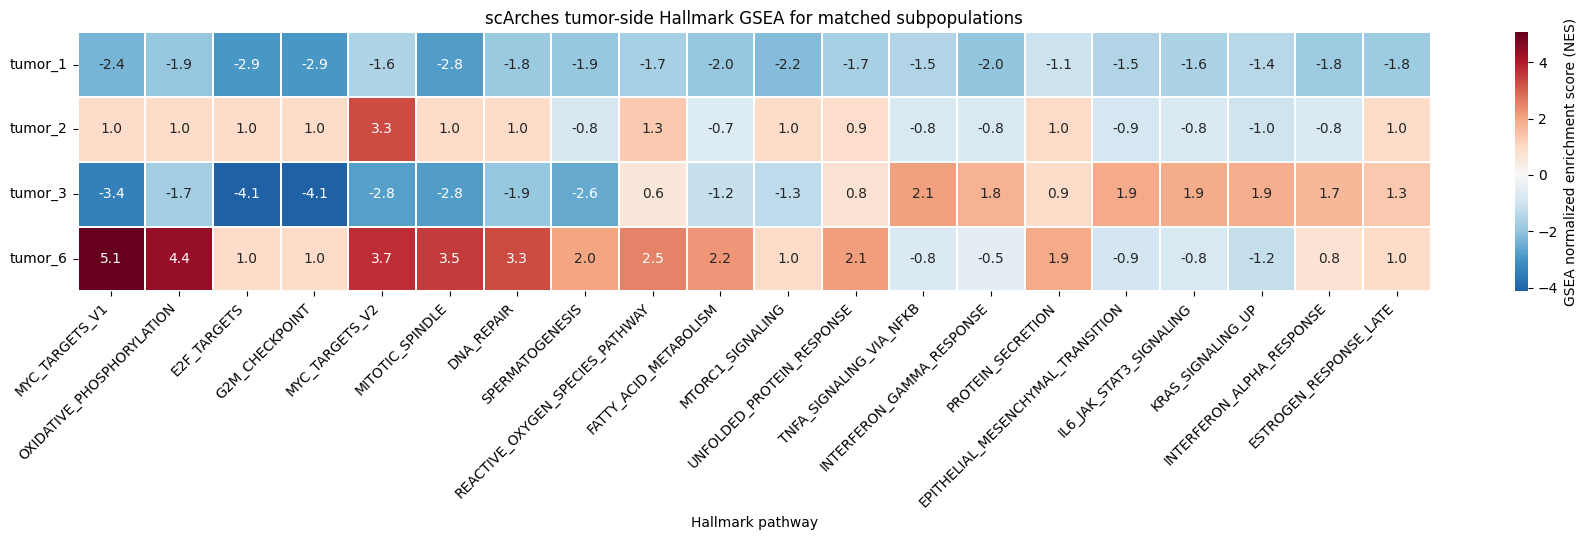

In [9]:
selected_tumor_subpops = [
    group for group in TUMOR_ORDER
    if group in (set(line_matches["primary_match"]) | set(line_matches["second_match"]))
]
gsea_focus = results_gsea_tumor.loc[
    results_gsea_tumor["subpopulation"].isin(selected_tumor_subpops)
].copy()

pathway_strength = (
    gsea_focus.groupby("pathway")["nes"]
    .apply(lambda values: values.abs().max())
    .sort_values(ascending=False)
)
gsea_pathways = pathway_strength.head(20).index.tolist()
gsea_heatmap = (
    gsea_focus[gsea_focus["pathway"].isin(gsea_pathways)]
    .pivot(index="subpopulation", columns="pathway", values="nes")
    .reindex(index=selected_tumor_subpops, columns=gsea_pathways)
)

fig, ax = plt.subplots(figsize=(18, 5.5))
sns.heatmap(
    gsea_heatmap,
    ax=ax,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.3,
    cbar_kws={"label": "GSEA normalized enrichment score (NES)"},
)
ax.set_title("scArches tumor-side Hallmark GSEA for matched subpopulations")
ax.set_xlabel("Hallmark pathway")
ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.tick_params(axis="y", labelrotation=0)
plt.tight_layout()
fig.savefig(FIG_DIR / "scarches_tumor_gsea_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# Bio2: MLM concordance

Loaded cached MLM concordance: /mnt/bigdisk/markus/CRC-scMFmap/models/validation/bio_scarches_cfg47/de_signatures/scarches_mlm_concordance.csv


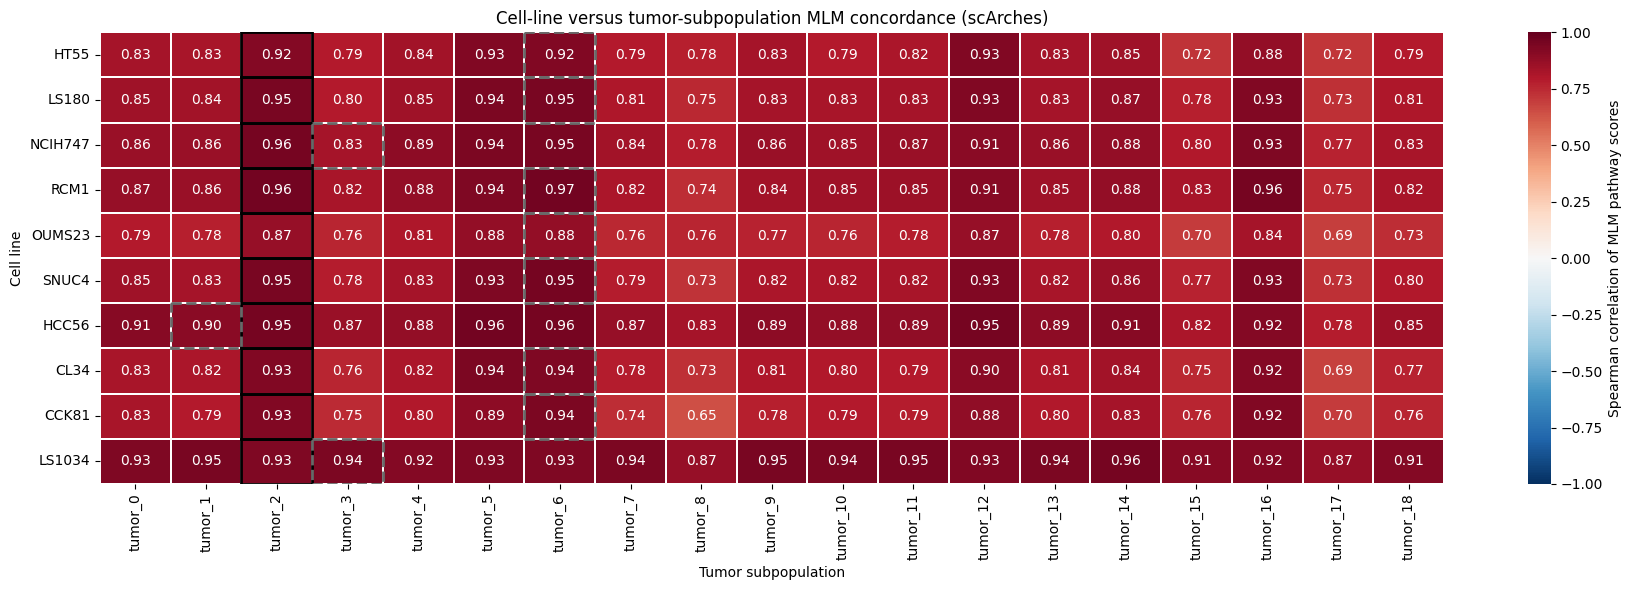

,cell_line,primary_match,runner_up,primary_rho,runner_up_rho,primary_minus_runner_up
0,CCK81,tumor_2,tumor_6,0.928,0.942,-0.015
1,LS1034,tumor_2,tumor_3,0.933,0.944,-0.011
2,SNUC4,tumor_2,tumor_6,0.946,0.954,-0.008
3,HT55,tumor_2,tumor_6,0.918,0.925,-0.007
4,CL34,tumor_2,tumor_6,0.929,0.935,-0.006
5,OUMS23,tumor_2,tumor_6,0.871,0.876,-0.005
6,LS180,tumor_2,tumor_6,0.948,0.951,-0.003
7,RCM1,tumor_2,tumor_6,0.962,0.966,-0.003
8,HCC56,tumor_2,tumor_1,0.954,0.904,0.050
9,NCIH747,tumor_2,tumor_3,0.956,0.834,0.122


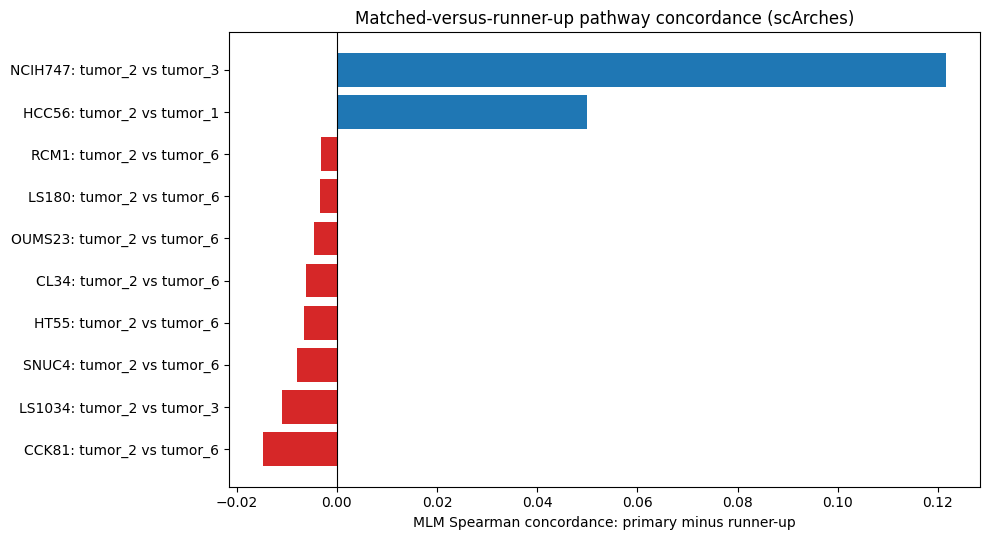

In [10]:
mlm_concordance_path = DE_DIR / "scarches_mlm_concordance.csv"
mlm_concordance = None

if mlm_concordance_path.exists() and not FORCE_RECOMPUTE:
    cached_matrix = pd.read_csv(mlm_concordance_path, index_col=0)
    cached_matrix = cached_matrix.reindex(index=LINE_ORDER, columns=TUMOR_ORDER)
    if cached_matrix.notna().all().all():
        mlm_concordance = cached_matrix
        print(f"Loaded cached MLM concordance: {mlm_concordance_path}")
    else:
        print("Cached MLM concordance does not cover the current groups; recomputing.")

if mlm_concordance is None:
    assert MLM_ARTIFACT.exists(), f"Run the joint biological notebook first: {MLM_ARTIFACT}"
    mlm = ad.read_h5ad(MLM_ARTIFACT)
    pathway_scores = pd.DataFrame(mlm.X, index=mlm.obs_names, columns=mlm.var_names)
    score_obs = pd.DataFrame(index=mlm.obs_names)
    score_obs["domain"] = combined_full.obs.loc[mlm.obs_names, "dataset"].astype(str)
    score_obs["group"] = combined_full.obs.loc[mlm.obs_names, "match_group_scarches"].astype(str)

    score_table = pathway_scores.join(score_obs[["domain", "group"]])
    group_scores = score_table.groupby(["domain", "group"], observed=True)[pathway_scores.columns].median()
    tumor_group_scores = group_scores.loc["tumor"]
    cell_line_group_scores = group_scores.loc["cell_line"]

    mlm_concordance = pd.DataFrame(index=LINE_ORDER, columns=TUMOR_ORDER, dtype=float)
    for cell_line in LINE_ORDER:
        for tumor_group in TUMOR_ORDER:
            mlm_concordance.loc[cell_line, tumor_group] = (
                cell_line_group_scores.loc["line_" + cell_line]
                .corr(tumor_group_scores.loc[tumor_group], method="spearman")
            )
    mlm_concordance.to_csv(mlm_concordance_path)
    print(f"Saved MLM concordance: {mlm_concordance_path}")

fig, ax = plt.subplots(figsize=(18, 6))
sns.heatmap(
    mlm_concordance,
    ax=ax,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.3,
    cbar_kws={"label": "Spearman correlation of MLM pathway scores"},
)
for y, cell_line in enumerate(LINE_ORDER):
    for group, color, linestyle in [
        (str(line_matches.loc[cell_line, "primary_match"]), "black", "-"),
        (str(line_matches.loc[cell_line, "second_match"]), "dimgray", "--"),
    ]:
        if group in TUMOR_ORDER:
            ax.add_patch(Rectangle(
                (TUMOR_ORDER.index(group), y), 1, 1, fill=False,
                edgecolor=color, linewidth=2.0, linestyle=linestyle,
            ))
ax.set_title("Cell-line versus tumor-subpopulation MLM concordance (scArches)")
ax.set_xlabel("Tumor subpopulation")
ax.set_ylabel("Cell line")
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
plt.tight_layout()
fig.savefig(FIG_DIR / "scarches_mlm_concordance.png", dpi=300, bbox_inches="tight")
plt.show()

runner_up_rows = []
for cell_line in LINE_ORDER:
    primary = str(line_matches.loc[cell_line, "primary_match"])
    runner_up = str(line_matches.loc[cell_line, "second_match"])
    primary_rho = float(mlm_concordance.loc[cell_line, primary])
    runner_up_rho = float(mlm_concordance.loc[cell_line, runner_up])
    runner_up_rows.append({
        "cell_line": cell_line,
        "primary_match": primary,
        "runner_up": runner_up,
        "primary_rho": primary_rho,
        "runner_up_rho": runner_up_rho,
        "primary_minus_runner_up": primary_rho - runner_up_rho,
    })
runner_up = pd.DataFrame(runner_up_rows).sort_values("primary_minus_runner_up").reset_index(drop=True)
runner_up.to_csv(DE_DIR / "scarches_mlm_primary_runner_up.csv", index=False)
display(runner_up.round(3))

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = np.where(runner_up["primary_minus_runner_up"] >= 0, "tab:blue", "tab:red")
labels = runner_up["cell_line"] + ": " + runner_up["primary_match"] + " vs " + runner_up["runner_up"]
ax.barh(labels, runner_up["primary_minus_runner_up"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("MLM Spearman concordance: primary minus runner-up")
ax.set_ylabel("")
ax.set_title("Matched-versus-runner-up pathway concordance (scArches)")
plt.tight_layout()
fig.savefig(FIG_DIR / "scarches_mlm_primary_runner_up.png", dpi=300, bbox_inches="tight")
plt.show()

# Bio3: signature view

In [11]:
line_vs_tumor_path = LINE_VS_TUMOR_DIR / "hallmark_prerank_line_vs_tumor.csv"
line_groups = sorted(pd.unique(cell_lines[is_line]))

if line_vs_tumor_path.exists() and not FORCE_RECOMPUTE:
    results_gsea_line_vs_tumor = pd.read_csv(line_vs_tumor_path)
    print(f"Loaded cached line-vs-tumor GSEA: {line_vs_tumor_path}")
else:
    collected = []
    for cell_line in line_groups:
        for subpopulation in TUMOR_ORDER:
            part_path = GSEA_DIR / f"gsea_line_{cell_line}_{subpopulation}.csv"
            if part_path.exists() and not FORCE_RECOMPUTE:
                collected.append(pd.read_csv(part_path))
                continue

            ranking_path = LINE_VS_TUMOR_DIR / f"ranking_{cell_line}_{subpopulation}.csv"
            if ranking_path.exists() and not FORCE_RECOMPUTE:
                ranking = pd.read_csv(ranking_path)
            else:
                combined_hvg, model = get_model_inputs()
                print(f"running DE: {cell_line} vs {subpopulation}")
                idx1 = is_line & (cell_lines == cell_line)
                idx2 = is_tumor & (group_values == subpopulation)
                de = model.differential_expression(
                    adata=combined_hvg,
                    batch_correction=True,
                    idx1=idx1,
                    idx2=idx2,
                    mode="change",
                    delta=0.25,
                    silent=True,
                )
                de.index.name = "gene"
                de = de.reset_index()
                de.to_csv(LINE_VS_TUMOR_DIR / f"scvi_de_{cell_line}_{subpopulation}.csv", index=False)
                ranking = make_lfc_ranking(de)
                ranking.to_csv(ranking_path, index=False)

            print(f"running GSEA: {cell_line} vs {subpopulation}")
            res = run_hallmark_prerank(ranking, f"{cell_line}-vs-{subpopulation}")
            res.insert(0, "cell_line", cell_line)
            res.insert(1, "subpop", subpopulation)
            res.to_csv(part_path, index=False)
            collected.append(res)
    results_gsea_line_vs_tumor = pd.concat(collected, ignore_index=True)
    results_gsea_line_vs_tumor.to_csv(line_vs_tumor_path, index=False)
    print(f"Saved line-vs-tumor GSEA: {line_vs_tumor_path}")

print(f"Comparisons: {results_gsea_line_vs_tumor['cell_line'].nunique()} lines x "
      f"{results_gsea_line_vs_tumor['subpop'].nunique()} subpopulations")
display(results_gsea_line_vs_tumor.head(3))

Loaded cached line-vs-tumor GSEA: /mnt/bigdisk/markus/CRC-scMFmap/models/validation/bio_scarches_cfg47/de_signatures/line_vs_tumor/hallmark_prerank_line_vs_tumor.csv
Comparisons: 10 lines x 19 subpopulations


,cell_line,subpop,Name,pathway,es,nes,nom_pval,fdr_qval,fwer_pval,tag_pct,gene_pct,lead_genes,set_size,overlap,comparison
0,CCK81,tumor_0,prerank,MITOTIC_SPINDLE,0.617277,4.338452,0.0,0.0,0.0,32/83,2.70%,TOP2A;PLK1;AURKA;NUSAP1;PIF1;BIRC5;CDK1;KIF23;...,199,83,CCK81-vs-tumor_0
1,CCK81,tumor_0,prerank,DNA_REPAIR,0.650804,3.722968,0.0,0.0,0.0,43/67,14.38%,ZWINT;ALYREF;NME1;POLR2G;RPA3;SAC3D1;HPRT1;GTF...,150,67,CCK81-vs-tumor_0
2,CCK81,tumor_0,prerank,OXIDATIVE_PHOSPHORYLATION,0.535424,3.573400,0.0,0.0,0.0,38/58,16.50%,TIMM10;FH;TIMM50;HSD17B10;VDAC3;MRPS22;MRPS15;...,200,58,CCK81-vs-tumor_0


Shared proliferation terms excluded in the sensitivity: []


,primary_match,second_match,all Hallmark: best,all Hallmark: primary rank,all Hallmark: runner-up rank,excluding shared proliferation: best,excluding shared proliferation: primary rank,excluding shared proliferation: runner-up rank
cell_line,,,,,,,,
HT55,tumor_2,tumor_6,tumor_2,1,3,tumor_2,1,3
LS180,tumor_2,tumor_6,tumor_2,1,3,tumor_2,1,3
NCIH747,tumor_2,tumor_3,tumor_2,1,9,tumor_2,1,9
RCM1,tumor_2,tumor_6,tumor_2,1,2,tumor_2,1,2
OUMS23,tumor_2,tumor_6,tumor_2,1,3,tumor_2,1,3
SNUC4,tumor_2,tumor_6,tumor_2,1,2,tumor_2,1,2
HCC56,tumor_2,tumor_1,tumor_5,2,13,tumor_5,2,13
CL34,tumor_2,tumor_6,tumor_2,1,2,tumor_2,1,2
CCK81,tumor_2,tumor_6,tumor_6,2,1,tumor_6,2,1


all Hallmark: median primary rank 1.0 (null 10.0), top-1 rate 70%, permutation p = 0.000
excluding shared proliferation: median primary rank 1.0 (null 10.0), top-1 rate 70%, permutation p = 0.000


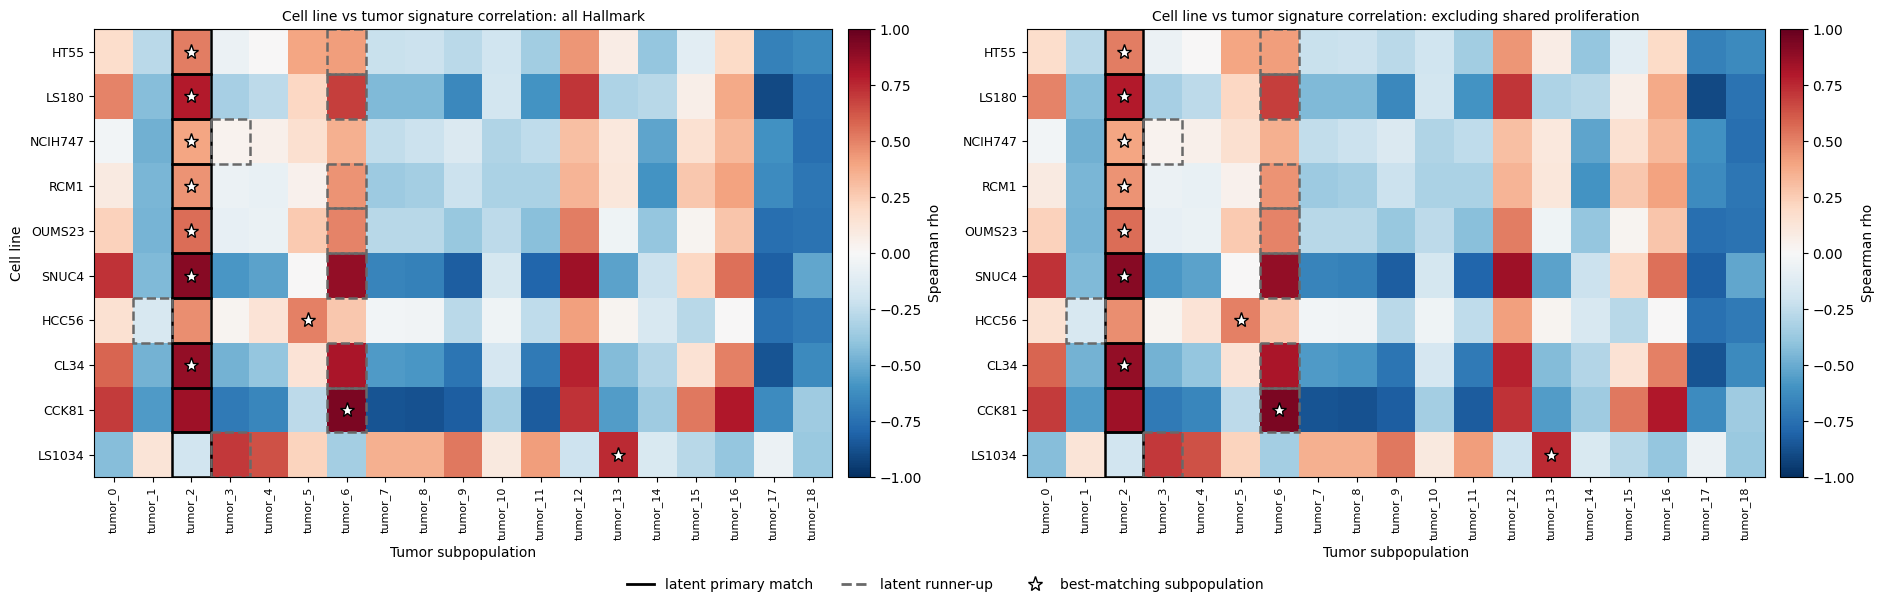

In [12]:
gsea_line_labels = LINE_ORDER
gsea_tumor_labels = [group for group in TUMOR_ORDER if group in set(results_gsea_tumor["subpopulation"])]

line_signature = (
    results_gsea_line_vs_tumor
    .groupby(["cell_line", "pathway"], observed=True)["nes"]
    .mean()
    .unstack("pathway")
    .loc[gsea_line_labels]
)
subpop_signature = (
    results_gsea_tumor
    .pivot_table(index="pathway", columns="subpopulation", values="nes")
    .loc[:, gsea_tumor_labels]
)
signature_pathways = line_signature.columns.intersection(subpop_signature.index)
line_signature = line_signature.loc[:, signature_pathways]
subpop_signature = subpop_signature.loc[signature_pathways]

shared_proliferation = []
if len(prolif_arm) >= 2:
    prolif_shared = (
        results_gsea_tumor[
            results_gsea_tumor["subpopulation"].isin(prolif_arm)
            & results_gsea_tumor["fdr_qval"].le(0.05)
            & results_gsea_tumor["nes"].abs().ge(1.0)
        ]
        .groupby("pathway")["nes"]
        .apply(lambda v: len(v) == len(prolif_arm) and bool((v > 0).all()))
    )
    shared_proliferation = sorted(p for p, flag in prolif_shared.items() if bool(flag))
print(f"Shared proliferation terms excluded in the sensitivity: {shared_proliferation}")


def signature_similarity(exclude=()):
    keep = [p for p in signature_pathways if p not in set(exclude)]
    return pd.DataFrame({
        cell_line: {
            subpop: line_signature.loc[cell_line, keep].corr(
                subpop_signature.loc[keep, subpop], method="spearman"
            )
            for subpop in gsea_tumor_labels
        }
        for cell_line in gsea_line_labels
    }).T


signature_sets = {
    "all Hallmark": signature_similarity(),
    "excluding shared proliferation": signature_similarity(shared_proliferation),
}

readout_rows = []
for cell_line in gsea_line_labels:
    primary = str(line_matches.loc[cell_line, "primary_match"])
    second = str(line_matches.loc[cell_line, "second_match"])
    record = {"cell_line": cell_line, "primary_match": primary, "second_match": second}
    for name, similarity in signature_sets.items():
        order = similarity.loc[cell_line].sort_values(ascending=False)
        record[f"{name}: best"] = order.index[0]
        record[f"{name}: primary rank"] = int(order.index.get_loc(primary)) + 1
        record[f"{name}: runner-up rank"] = int(order.index.get_loc(second)) + 1
    readout_rows.append(record)
signature_readout = pd.DataFrame(readout_rows).set_index("cell_line")
signature_readout.to_csv(DE_DIR / "scarches_signature_readout.csv")
display(signature_readout)

rng = np.random.default_rng(SEED)
null = rng.integers(1, len(gsea_tumor_labels) + 1, size=(1000, len(gsea_line_labels)))
for name in signature_sets:
    observed = signature_readout[f"{name}: primary rank"].to_numpy()
    p_value = float((np.median(null, axis=1) <= np.median(observed)).mean())
    print(
        f"{name}: median primary rank {np.median(observed):.1f} "
        f"(null {0.5 * (len(gsea_tumor_labels) + 1):.1f}), "
        f"top-1 rate {(observed == 1).mean():.0%}, permutation p = {p_value:.3f}"
    )

fig, axes = plt.subplots(ncols=len(signature_sets), figsize=(9.5 * len(signature_sets), 5.8))
for ax, (name, similarity) in zip(axes, signature_sets.items()):
    values = similarity.loc[gsea_line_labels, gsea_tumor_labels]
    image = ax.imshow(
        values.to_numpy(float), aspect="auto", cmap="RdBu_r",
        vmin=-1, vmax=1, interpolation="nearest",
    )
    ax.set_xticks(np.arange(len(gsea_tumor_labels)))
    ax.set_xticklabels(gsea_tumor_labels, rotation=90, fontsize=8)
    ax.set_yticks(np.arange(len(gsea_line_labels)))
    ax.set_yticklabels(gsea_line_labels, fontsize=9)
    ax.set_xlabel("Tumor subpopulation")
    ax.set_title(f"Cell line vs tumor signature correlation: {name}", fontsize=10)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.02).set_label("Spearman rho")

    for y, cell_line in enumerate(gsea_line_labels):
        for group, color, linestyle in [
            (str(line_matches.loc[cell_line, "primary_match"]), "black", "-"),
            (str(line_matches.loc[cell_line, "second_match"]), "dimgray", "--"),
        ]:
            if group in gsea_tumor_labels:
                x = gsea_tumor_labels.index(group)
                ax.add_patch(Rectangle(
                    (x - 0.5, y - 0.5), 1, 1, fill=False,
                    edgecolor=color, linewidth=1.8, linestyle=linestyle,
                ))
        best = values.loc[cell_line].idxmax()
        ax.plot(
            gsea_tumor_labels.index(best), y, marker="*", color="white",
            markeredgecolor="black", markersize=11, zorder=5,
        )

    previous_primary = None
    for y, cell_line in enumerate(gsea_line_labels):
        primary = str(line_matches.loc[cell_line, "primary_match"])
        if previous_primary is not None and primary != previous_primary:
            ax.axhline(y - 0.5, color="black", linewidth=1.2)
        previous_primary = primary

axes[0].set_ylabel("Cell line")
fig.legend(
    handles=[
        Line2D([0], [0], color="black", lw=2, label="latent primary match"),
        Line2D([0], [0], color="dimgray", lw=2, linestyle="--", label="latent runner-up"),
        Line2D([0], [0], marker="*", color="white", markeredgecolor="black",
               linestyle="", markersize=11, label="best-matching subpopulation"),
    ],
    loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.05),
)
plt.tight_layout()
fig.savefig(FIG_DIR / "scarches_signature_match.png", dpi=300, bbox_inches="tight")
plt.show()

# Summary

In [13]:
summary = line_matches[["n_cells", "primary_match", "primary_frac", "second_match", "margin",
                        "median_dist_nearest_tumor", "low_proximity"]].copy()
summary["joint_primary"] = joint_matches["primary_match"]
summary["joint_margin"] = joint_matches["margin"]
summary["same_primary_as_joint"] = summary["primary_match"].eq(summary["joint_primary"])
summary["mlm_primary_rho"] = [
    float(mlm_concordance.loc[cl, line_matches.loc[cl, "primary_match"]]) for cl in summary.index
]
summary["mlm_runner_up_rho"] = [
    float(mlm_concordance.loc[cl, line_matches.loc[cl, "second_match"]]) for cl in summary.index
]
summary["signature_best"] = signature_readout["all Hallmark: best"]
summary["signature_primary_rank"] = signature_readout["all Hallmark: primary rank"]
summary = summary.loc[LINE_ORDER]
summary.to_csv(DE_DIR / "scarches_summary.csv")
display(summary.round(3))

print(f"Low proximity: {summary.index[summary['low_proximity']].tolist()}")
print(f"Same primary as joint: {int(summary['same_primary_as_joint'].sum())} / 10")
print(f"Signature best = latent primary: "
      f"{int((summary['signature_best'] == summary['primary_match']).sum())} / 10")

,n_cells,primary_match,primary_frac,second_match,margin,median_dist_nearest_tumor,low_proximity,joint_primary,joint_margin,same_primary_as_joint,mlm_primary_rho,mlm_runner_up_rho,signature_best,signature_primary_rank
cell_line,,,,,,,,,,,,,,
HT55,211,tumor_2,0.815,tumor_6,0.722,1.208,False,tumor_4,0.196,False,0.918,0.925,tumor_2,1
LS180,362,tumor_2,0.790,tumor_6,0.710,1.118,False,tumor_4,0.141,False,0.948,0.951,tumor_2,1
NCIH747,80,tumor_2,0.807,tumor_3,0.707,1.346,False,tumor_5,0.123,False,0.956,0.834,tumor_2,1
RCM1,131,tumor_2,0.741,tumor_6,0.660,1.523,True,tumor_5,0.289,False,0.962,0.966,tumor_2,1
OUMS23,107,tumor_2,0.706,tumor_6,0.589,1.702,True,tumor_6,0.192,False,0.871,0.876,tumor_2,1
SNUC4,471,tumor_2,0.741,tumor_6,0.562,0.934,False,tumor_5,0.020,False,0.946,0.954,tumor_2,1
HCC56,102,tumor_2,0.628,tumor_1,0.531,1.091,False,tumor_4,0.268,False,0.954,0.904,tumor_5,2
CL34,418,tumor_2,0.731,tumor_6,0.527,0.970,False,tumor_4,0.022,False,0.929,0.935,tumor_2,1
CCK81,127,tumor_2,0.638,tumor_6,0.305,0.876,False,tumor_5,0.256,False,0.928,0.942,tumor_6,2


Low proximity: [np.str_('RCM1'), np.str_('OUMS23')]
Same primary as joint: 0 / 10
Signature best = latent primary: 7 / 10
